# SupplyGuard AI — Supply Chain Disruption Risk Prediction & Early Warning System

**End-to-end notebook**: preprocessing → EDA → feature engineering → model comparison → evaluation → Predict-Explain-Recommend demo.

Dataset: `data/global_supply_chain_risk_logistics.csv` (5,000 shipment records, synthetic but domain-realistic).

Pipeline modules live in `../src/` and are reused here so the notebook and the live dashboard always stay in sync.


In [1]:
import sys, os
sys.path.append(os.path.abspath('../src'))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)


## 1. Load raw data

In [2]:
raw = pd.read_csv('../data/global_supply_chain_risk_logistics.csv')
print(raw.shape)
raw.head()


(5008, 25)


,Shipment_ID,Region,Country,Product_Category,Supplier_Tier,Transport_Mode,Lead_Time_Days,Distance_KM,Order_Quantity,Inventory_Level_Days,Demand_Variability_Pct,Supplier_Reliability_Score,Financial_Stability_Score,Geopolitical_Risk_Index,Weather_Risk_Index,Port_Congestion_Index,Fuel_Price_Index,Customs_Delay_Days,Disruption_Events_Past_Year,On_Time_Delivery_Rate_Pct,Cost_Variance_Pct,Single_Sourcing_Flag,Contract_Flexibility_Score,Latent_Risk_Score,Risk_Level
0,SG02088,South Asia,Bangladesh,Textiles,Tier 2,Air,8,3543,282,21.5,19.5,0.777,0.245,0.264,0.473,0.000,0.461,1.21,4,95.9,0.1,0,0.739,0.345,Medium
1,SG01202,Middle East,Turkey,Semiconductors,Tier 2,Air,1,5233,90,1.9,15.9,0.714,0.644,0.413,0.181,0.045,0.600,0.05,2,97.6,12.6,0,0.786,0.172,Low
2,SG04995,Europe,Germany,Automotive Parts,Tier 1,Sea,34,8623,653,26.0,21.7,0.528,0.706,0.255,0.174,0.563,0.703,1.49,2,100.0,18.3,0,0.608,0.315,Low
3,SG04819,North America,Mexico,Consumer Goods,Tier 2,Sea,36,6817,86,22.3,27.0,0.559,0.631,0.354,0.220,0.686,0.417,2.49,3,95.8,13.9,0,0.852,0.322,Low
4,SG03527,East Asia,Japan,Automotive Parts,Tier 2,Air,8,7391,76,10.1,17.3,0.817,0.839,0.259,0.390,0.001,0.380,2.87,5,73.8,10.9,1,0.000,0.295,Low


In [3]:
raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 5008 entries, 0 to 5007
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Shipment_ID                  5008 non-null   str    
 1   Region                       5008 non-null   str    
 2   Country                      5008 non-null   str    
 3   Product_Category             5008 non-null   str    
 4   Supplier_Tier                5008 non-null   str    
 5   Transport_Mode               5008 non-null   str    
 6   Lead_Time_Days               5008 non-null   int64  
 7   Distance_KM                  5008 non-null   int64  
 8   Order_Quantity               5008 non-null   int64  
 9   Inventory_Level_Days         4908 non-null   float64
 10  Demand_Variability_Pct       5008 non-null   float64
 11  Supplier_Reliability_Score   5008 non-null   float64
 12  Financial_Stability_Score    4858 non-null   float64
 13  Geopolitical_Risk_Index      

## 2. Preprocessing

Handles duplicates, missing values (median/mode imputation), and defensive range clipping.

In [4]:
from preprocessing import preprocess

clean_df, meta = preprocess(raw)
print(meta)
clean_df.to_csv('../data/clean_supply_chain_data.csv', index=False)
clean_df.shape


{'duplicates_removed': 8, 'missing_before': {'Inventory_Level_Days': 100, 'Financial_Stability_Score': 150, 'Customs_Delay_Days': 100, 'Contract_Flexibility_Score': 125}, 'rows_after': 5000}


(5000, 25)

## 3. Exploratory Data Analysis

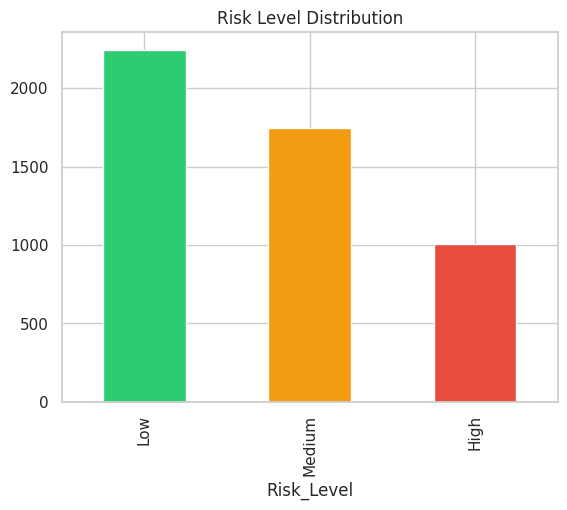

In [5]:
clean_df['Risk_Level'].value_counts().plot(kind='bar', color=['#2ecc71','#f39c12','#e74c3c'])
plt.title('Risk Level Distribution')
plt.show()


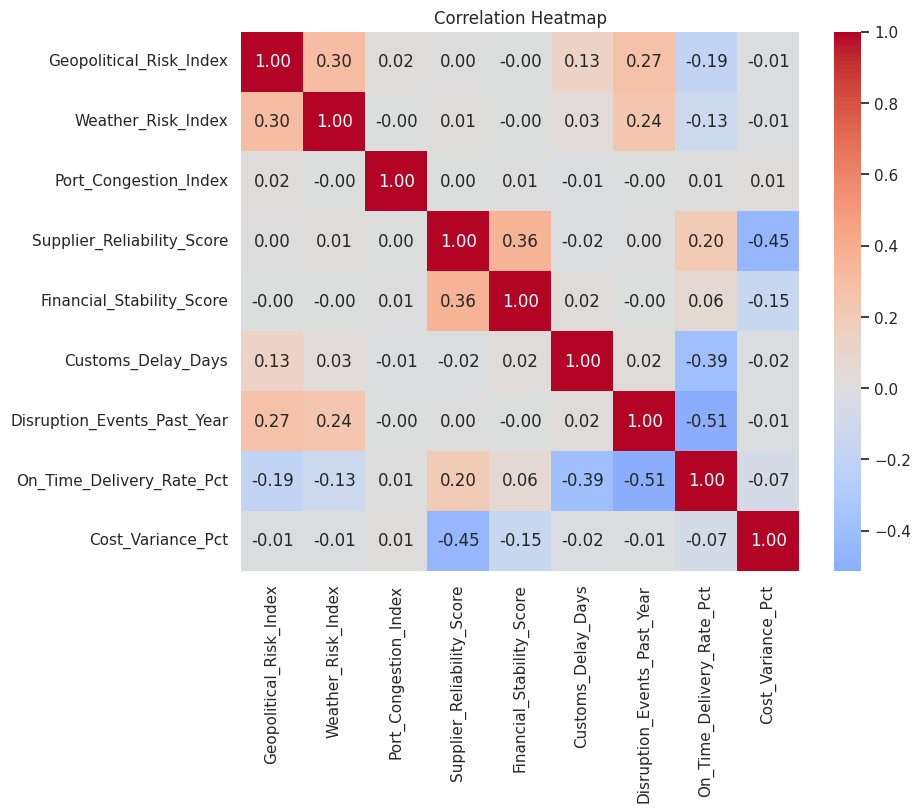

In [6]:
num_cols = ['Geopolitical_Risk_Index','Weather_Risk_Index','Port_Congestion_Index',
            'Supplier_Reliability_Score','Financial_Stability_Score','Customs_Delay_Days',
            'Disruption_Events_Past_Year','On_Time_Delivery_Rate_Pct','Cost_Variance_Pct']
plt.figure(figsize=(9,7))
sns.heatmap(clean_df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()


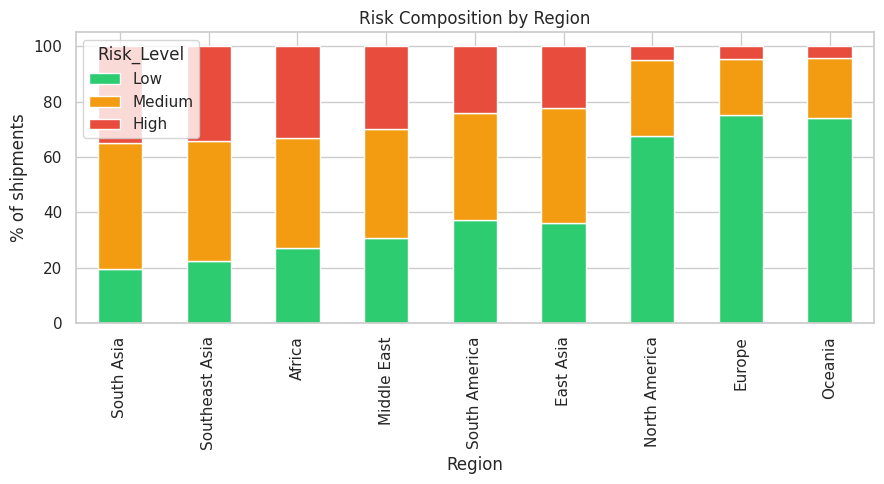

In [7]:
fig, ax = plt.subplots(figsize=(9,5))
region_risk = pd.crosstab(clean_df['Region'], clean_df['Risk_Level'], normalize='index') * 100
region_risk = region_risk[['Low','Medium','High']]
region_risk.sort_values('High', ascending=False).plot(kind='bar', stacked=True,
    color=['#2ecc71','#f39c12','#e74c3c'], ax=ax)
plt.ylabel('% of shipments')
plt.title('Risk Composition by Region')
plt.tight_layout()
plt.show()


### Key EDA observations
- Risk levels are realistically imbalanced (~45% Low, ~35% Medium, ~20% High) rather than artificially balanced.
- Geopolitical and weather risk indices are the strongest positive correlates of the Early Warning Score.
- Supplier reliability and financial stability are the strongest *negative* correlates — more reliable, financially
  stable suppliers materially reduce exposure.
- Regions differ meaningfully in risk composition, supporting region-level mitigation strategies.


## 4. Feature Engineering

Builds 7 explainable composite risk sub-scores and the transparent, weighted **Early Warning Score (EWS)**.

In [8]:
from feature_engineering import engineer_features, FEATURE_WEIGHTS_DOC

fe_df, encoders, weights = engineer_features(clean_df)
print(FEATURE_WEIGHTS_DOC)
fe_df.to_csv('../data/feature_engineered_data.csv', index=False)
fe_df[['Early_Warning_Score','EWS_Band']].describe(include='all')



Early Warning Score (EWS) formula — fully transparent, 0-100 scale:

EWS = 0.20*Geo_Weather_Exposure + 0.18*Supplier_Weakness_Score
    + 0.16*Logistics_Friction_Score + 0.12*Demand_Volatility_Score
    + 0.12*Concentration_Risk_Score + 0.14*Historical_Instability_Score
    + 0.08*Cost_Pressure_Score

Bands: Safe (<35) | Watch (35-54) | Elevated (55-74) | Critical (75-100)



,Early_Warning_Score,EWS_Band
count,5000.000000,5000
unique,NaN,4
top,NaN,Safe
freq,NaN,2249
mean,47.737200,NaN
std,15.126772,NaN
min,0.000000,NaN
25%,37.100000,NaN
50%,47.300000,NaN
75%,57.925000,NaN


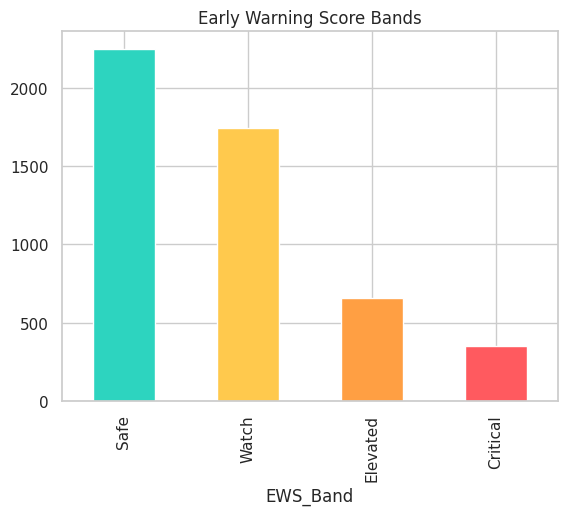

In [9]:
fe_df['EWS_Band'].value_counts().reindex(['Safe','Watch','Elevated','Critical']).plot(
    kind='bar', color=['#2DD4BF','#FFC94D','#FF9F43','#FF5A5F'])
plt.title('Early Warning Score Bands')
plt.show()


## 5. Model Training & Comparison

Seven classifiers are trained to predict `Risk_Level` (Low / Medium / High) from the engineered feature set, and compared on Accuracy, Precision, Recall, weighted F1, and ROC-AUC (one-vs-rest).

In [10]:
# Full training pipeline lives in ../src/train_models.py — run it here for a fresh comparison
!cd ../src && python3 train_models.py


                 Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
0  Logistic Regression     0.678     0.6749   0.678    0.6748   0.8496
1        Random Forest     0.670     0.6781   0.670    0.6689   0.8391
2    Gradient Boosting     0.662     0.6601   0.662    0.6597   0.8372
3              XGBoost     0.649     0.6474   0.649    0.6478   0.8285
4            SVM (RBF)     0.648     0.6502   0.648    0.6472   0.8385
5        Decision Tree     0.624     0.6250   0.624    0.6239   0.7584
6                  KNN     0.622     0.6128   0.622    0.6067   0.8028

Best model: Logistic Regression



Artifacts saved to /home/claude/SupplyGuard_AI/models


In [11]:
import json
with open('../models/model_comparison.json') as f:
    comparison = json.load(f)

results_df = pd.DataFrame(comparison['results'])
results_df


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.678,0.6749,0.678,0.6748,0.8496
1,Random Forest,0.670,0.6781,0.670,0.6689,0.8391
2,Gradient Boosting,0.662,0.6601,0.662,0.6597,0.8372
3,XGBoost,0.649,0.6474,0.649,0.6478,0.8285
4,SVM (RBF),0.648,0.6502,0.648,0.6472,0.8385
5,Decision Tree,0.624,0.6250,0.624,0.6239,0.7584
6,KNN,0.622,0.6128,0.622,0.6067,0.8028


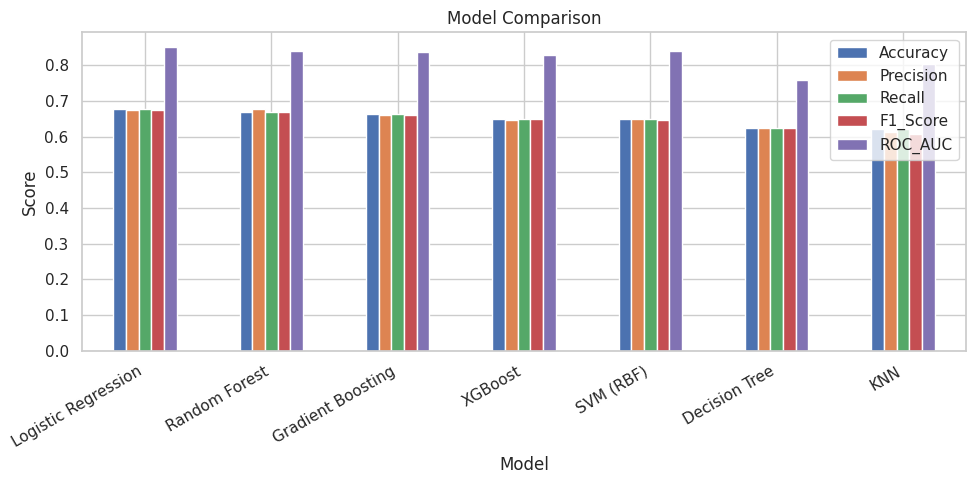

Best model: Logistic Regression


In [12]:
results_df.set_index('Model')[['Accuracy','Precision','Recall','F1_Score','ROC_AUC']].plot(
    kind='bar', figsize=(10,5))
plt.title('Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()
print('Best model:', comparison['best_model'])


## 6. Evaluation — Confusion Matrix & Feature Importance

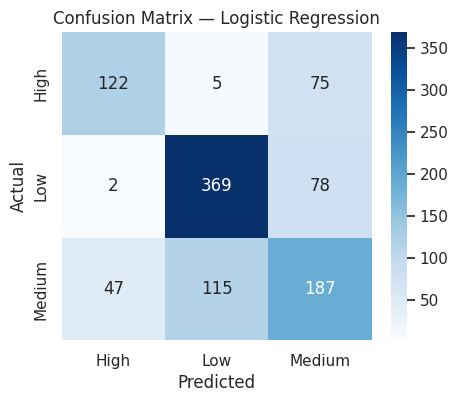

In [13]:
cm = np.array(comparison['confusion_matrix'])
labels = comparison['class_names']
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f"Confusion Matrix — {comparison['best_model']}")
plt.show()


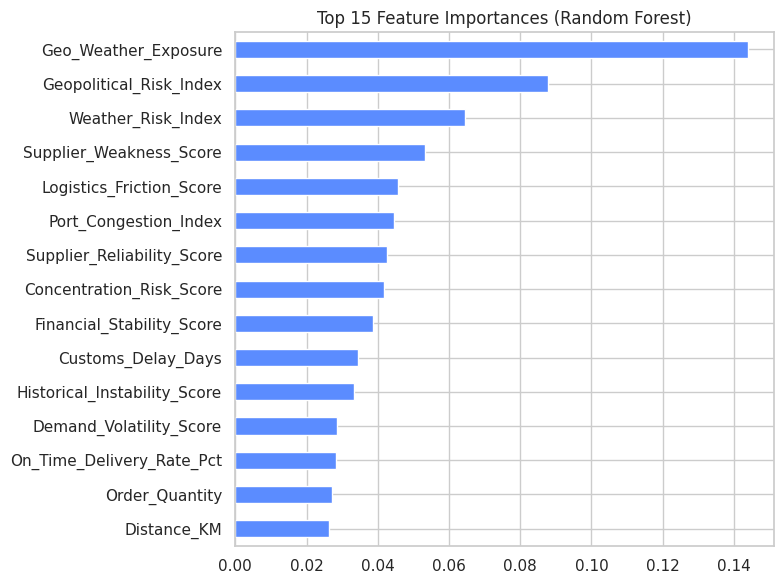

In [14]:
fi = pd.Series(comparison['feature_importances']).sort_values(ascending=False).head(15)
plt.figure(figsize=(8,6))
fi[::-1].plot(kind='barh', color='#5B8CFF')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.tight_layout()
plt.show()


## 7. Predict → Explain → Recommend Demo

This mirrors exactly what the Streamlit dashboard does for a single shipment.

In [15]:
sys.path.append(os.path.abspath('../dashboard'))
from risk_engine import (load_artifacts, compute_composite_scores, compute_ews, ews_band,
                          explain, recommend, predict_ml)

model, scaler, target_encoder, feature_cols = load_artifacts()

sample = fe_df.sample(1, random_state=7).iloc[0].to_dict()
scores = compute_composite_scores(sample)
ews = compute_ews(scores)
band = ews_band(ews)
explanation = explain(scores, top_n=3)
recs = recommend(explanation)

label, proba = predict_ml(sample, model, scaler, target_encoder, feature_cols)

print('Shipment:', sample['Shipment_ID'])
print('Predicted Risk Level:', label, '| Probabilities:', proba)
print('Early Warning Score:', round(ews,1), '| Band:', band)
print('\nTop risk factors:')
for e in explanation:
    print(' -', e['factor'], f"({e['contribution_pct']}% of EWS)")
print('\nRecommended actions:')
for r in recs:
    print(f"\n[{r['factor']}]")
    for a in r['actions']:
        print('  •', a)


Shipment: SG00081
Predicted Risk Level: Low | Probabilities: {'High': 0.0077, 'Low': 0.8241, 'Medium': 0.1682}
Early Warning Score: 36.3 | Band: Watch

Top risk factors:
 - Logistics Friction (congestion, customs, lead time) (28.6% of EWS)
 - Geopolitical & Weather Exposure (24.4% of EWS)
 - Supplier Weakness (reliability + financial health) (17.6% of EWS)

Recommended actions:

[Logistics Friction (congestion, customs, lead time)]
  • Evaluate an alternate transport mode or route to bypass congested ports.
  • Pursue customs pre-clearance / trusted-trader programs to cut clearance delays.
  • Rebook with buffer lead time during peak congestion windows.

[Geopolitical & Weather Exposure]
  • Diversify sourcing across lower geopolitical-risk regions to reduce single-region exposure.
  • Set up automated geopolitical & weather-alert monitoring for this lane.
  • Pre-position safety stock ahead of known high-risk seasons (monsoon, hurricane, conflict cycles).

[Supplier Weakness (reliabil

## 8. Business Insights Summary

- **Regional hotspots**: certain regions (e.g. South/Southeast Asia, Middle East) consistently show higher average
  Early Warning Scores, driven by combined geopolitical and weather exposure.
- **Single-sourcing penalty**: single-sourced shipments carry a measurable EWS premium vs multi-sourced ones —
  a clear, actionable diversification signal.
- **Transport trade-offs**: sea freight has materially longer lead times (and more schedule risk) than air,
  informing which lanes deserve air-freight fallback plans during Critical-band events.
- **Model role**: the best model (weighted F1 ≈ 0.67, ROC-AUC ≈ 0.85) is a *triage* tool — it should accelerate
  human review of Elevated/Critical shipments, not replace judgment on individual high-stakes decisions.

The full interactive version of this analysis — including the What-If Simulator and live Risk Ranking — is in
`dashboard/app.py` (run with `streamlit run dashboard/app.py`).
